In [11]:
import pandas as pd
import numpy as np
from sklearn import tree
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/tabela - tabela.csv.csv', decimal=',')
df = df.drop(columns=['Data'])
df = df.dropna()


In [16]:
X = df.iloc[:,:3]
Y = df.iloc[:,-1]

In [17]:
X

,Temp. Ins. (C),Umi. Ins. (%),Radiacao (KJ/m²)
0,24.4,83,0.0
1,24.5,85,0.0
2,24.3,86,0.0
3,24.2,84,0.0
4,23.9,86,0.0
...,...,...,...
86,26.5,86,2076.3
87,25.8,86,1464.3
88,26.6,85,911.2
89,27.5,78,1327.1


In [18]:
Y

,Temperaturas alvos
0,23.0
1,23.1
2,23.2
3,23.3
4,23.4
...,...
86,31.6
87,31.7
88,31.8
89,31.9


In [19]:
minha_arvore = tree.DecisionTreeRegressor()

In [20]:
minha_arvore.fit(X,Y)

DecisionTreeRegressor()

[Text(0.5862116228070176, 0.9583333333333334, 'x[1] <= 92.5\nsquared_error = 6.9\nsamples = 91\nvalue = 27.5'),
 Text(0.32209429824561403, 0.875, 'x[0] <= 24.55\nsquared_error = 5.258\nsamples = 62\nvalue = 26.303'),
 Text(0.4541529605263158, 0.9166666666666667, 'True  '),
 Text(0.1425438596491228, 0.7916666666666666, 'x[1] <= 90.5\nsquared_error = 1.488\nsamples = 23\nvalue = 24.726'),
 Text(0.08333333333333333, 0.7083333333333334, 'x[0] <= 23.5\nsquared_error = 1.371\nsamples = 18\nvalue = 24.467'),
 Text(0.03508771929824561, 0.625, 'x[0] <= 23.1\nsquared_error = 0.012\nsamples = 4\nvalue = 23.65'),
 Text(0.017543859649122806, 0.5416666666666666, 'x[0] <= 22.9\nsquared_error = 0.003\nsamples = 2\nvalue = 23.75'),
 Text(0.008771929824561403, 0.4583333333333333, 'squared_error = 0.0\nsamples = 1\nvalue = 23.8'),
 Text(0.02631578947368421, 0.4583333333333333, 'squared_error = 0.0\nsamples = 1\nvalue = 23.7'),
 Text(0.05263157894736842, 0.5416666666666666, 'x[1] <= 88.0\nsquared_error = 

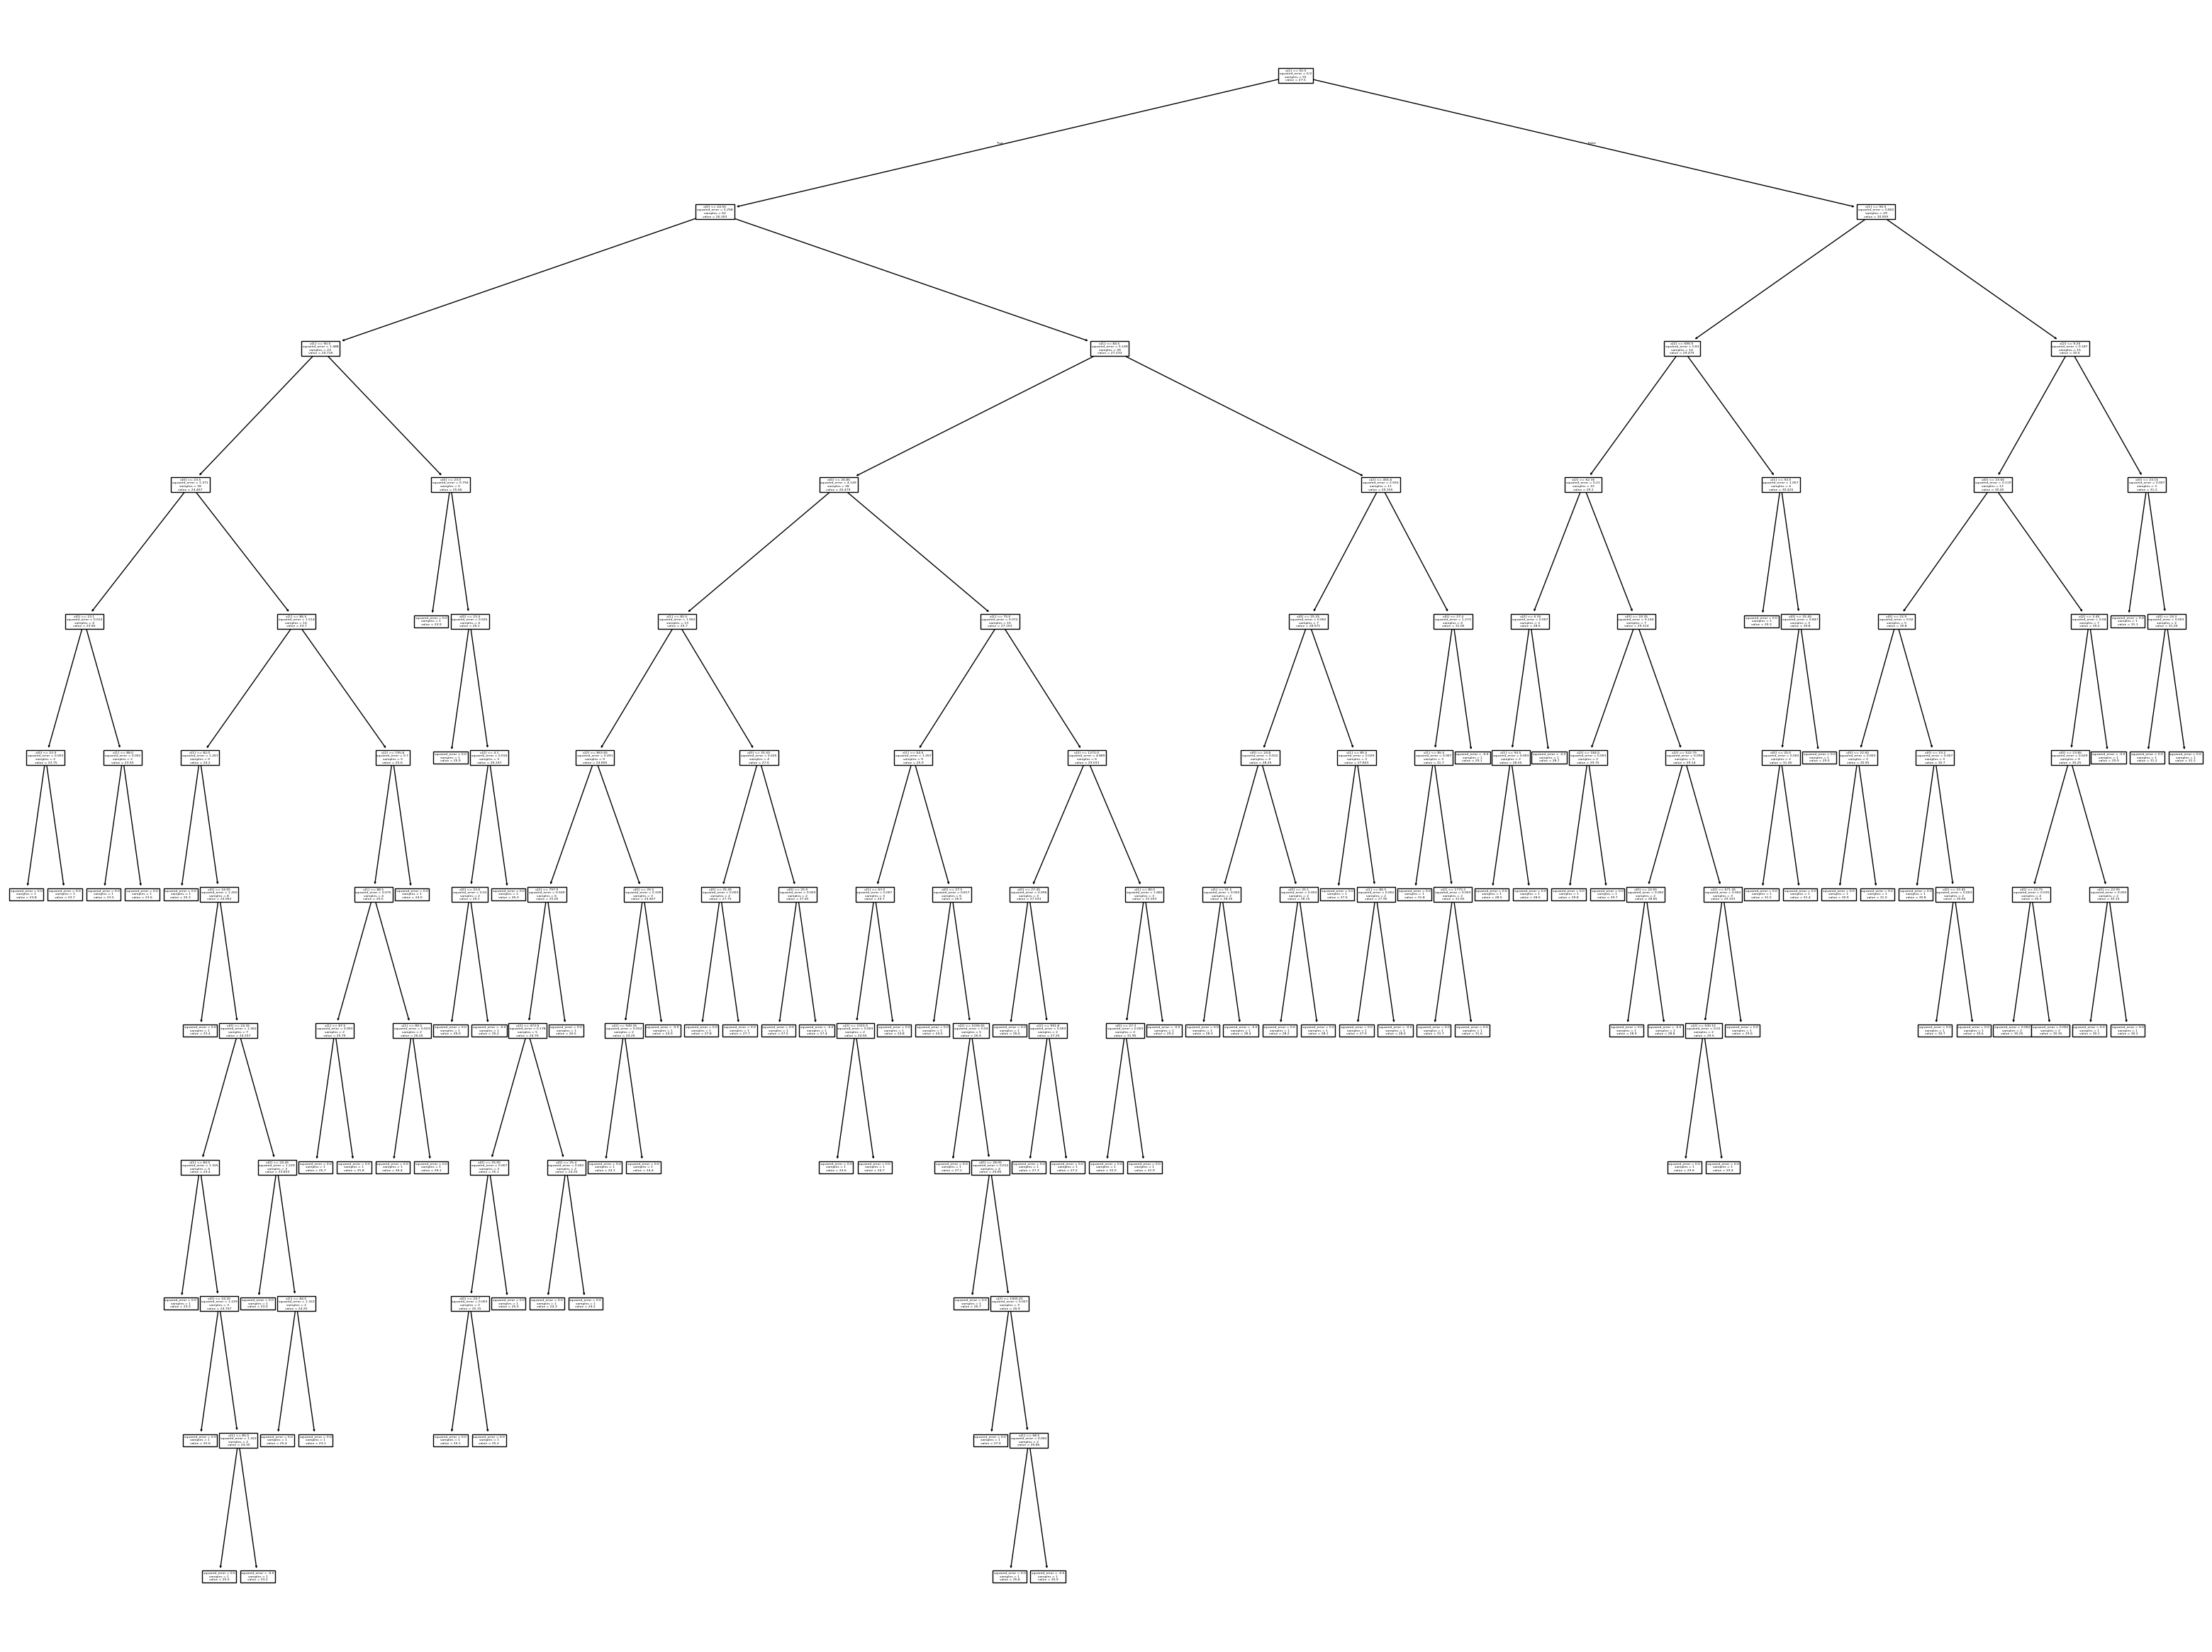

In [24]:
plt.figure(figsize=(40, 30))
tree.plot_tree(minha_arvore)

In [15]:
print(minha_arvore.criterion)

squared_error


In [22]:
regras = tree.export_text(
    minha_arvore,
    feature_names=list(X.columns),
    max_depth=minha_arvore.get_depth(),
    decimals=2
)

print(regras)

|--- Umi. Ins. (%) <= 92.50
|   |--- Temp. Ins. (C) <= 24.55
|   |   |--- Umi. Ins. (%) <= 90.50
|   |   |   |--- Temp. Ins. (C) <= 23.50
|   |   |   |   |--- Temp. Ins. (C) <= 23.10
|   |   |   |   |   |--- Temp. Ins. (C) <= 22.90
|   |   |   |   |   |   |--- value: [23.80]
|   |   |   |   |   |--- Temp. Ins. (C) >  22.90
|   |   |   |   |   |   |--- value: [23.70]
|   |   |   |   |--- Temp. Ins. (C) >  23.10
|   |   |   |   |   |--- Umi. Ins. (%) <= 88.00
|   |   |   |   |   |   |--- value: [23.50]
|   |   |   |   |   |--- Umi. Ins. (%) >  88.00
|   |   |   |   |   |   |--- value: [23.60]
|   |   |   |--- Temp. Ins. (C) >  23.50
|   |   |   |   |--- Umi. Ins. (%) <= 86.50
|   |   |   |   |   |--- Umi. Ins. (%) <= 82.00
|   |   |   |   |   |   |--- value: [25.30]
|   |   |   |   |   |--- Umi. Ins. (%) >  82.00
|   |   |   |   |   |   |--- Temp. Ins. (C) <= 24.05
|   |   |   |   |   |   |   |--- value: [23.40]
|   |   |   |   |   |   |--- Temp. Ins. (C) >  24.05
|   |   |   |   |   |  

In [23]:
with open("regras_arvore.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write(regras)